## IMPORT

In [58]:
import os
import glob
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import tensorflow as tf
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.layers import Flatten, Dense, Input
from tensorflow.keras.models import Model

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.utils import compute_class_weight

from keras.models import Sequential
from keras.layers import Dense, Input, Activation, Flatten
from keras.utils import set_random_seed
from tensorflow.keras.layers import RandomFlip, BatchNormalization
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## LOADING THE DATA

In [24]:
!mkdir -p ~/.kaggle
!cp "/content/kaggle (3).json" ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json
!pip install -q kaggle


cp: cannot stat '/content/kaggle (3).json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


In [25]:
!kaggle datasets download -d jangedoo/utkface-new -p /content/data --unzip

Dataset URL: https://www.kaggle.com/datasets/jangedoo/utkface-new
License(s): copyright-authors
100% 331M/331M [00:04<00:00, 75.6MB/s]



In [26]:
!ls /content/data

crop_part1  UTKFace  utkface_aligned_cropped


In [27]:
folder = '/content/data/UTKFace'
len(os.listdir(folder))

23708

In [28]:
path = '/content/data/UTKFace/'
image_paths = glob.glob(path + '*.jpg')
print(len(image_paths))
image_paths[0]

23708


'/content/data/UTKFace/38_1_0_20170104183625399.jpg.chip.jpg'

In [29]:
paths = []
ages = []

for path in image_paths:
    img_label = path.split('/')[-1].split('_')
    if len(img_label) == 4:
        try:
            age = int(img_label[0])
        except ValueError:
            continue
        ages.append(age)
        paths.append(path)

print(len(image_paths), len(paths))
print(paths[0], ages[0])

23708 23705
/content/data/UTKFace/38_1_0_20170104183625399.jpg.chip.jpg 38


## Preprocessing

In [30]:
def preprocess_image(path, age):
    img = tf.io.read_file(path)

    img = tf.image.decode_jpeg(img, channels=3)

    img = tf.image.resize(img, [64, 64]) / 255.0

    return img, age

In [31]:
ages_np = np.array(ages).astype('float32')
paths_np = np.array(paths)

In [32]:
keep = ages_np <= 100
ages_np, paths_np = ages_np[keep], paths_np[keep]

In [72]:
trian_paths, test_paths, train_ages, test_ages_split  = train_test_split(paths_np, ages_np, test_size=0.3, random_state=42)

In [34]:
bins = (train_ages // 5).astype(int)
cnt = np.bincount(bins)
w = 1.0 / np.sqrt(cnt[bins])
w = (w / w.mean()).astype('float32')

In [73]:
train_ds = (tf.data.Dataset.from_tensor_slices((trian_paths, train_ages, w))
            .shuffle(len(trian_paths), seed=42)
            .map(lambda p, a, wt: (*preprocess_image(p, a), wt))
            .batch(64).prefetch(tf.data.AUTOTUNE))

test_ds = (tf.data.Dataset.from_tensor_slices((test_paths, test_ages_split))
           .map(preprocess_image)
           .batch(64).prefetch(tf.data.AUTOTUNE))

## LOCKING TO THE DATA

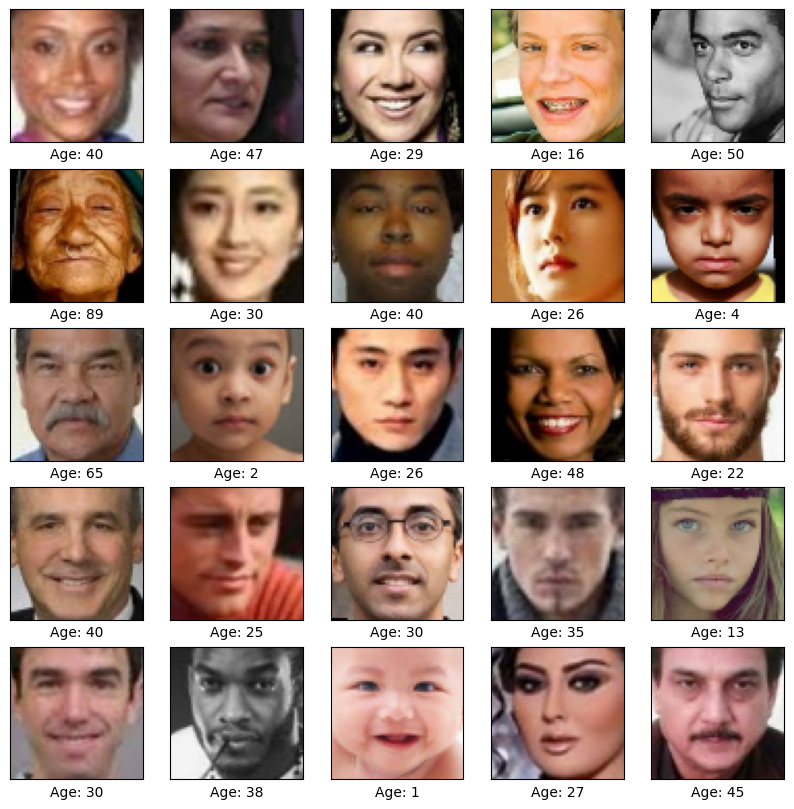

In [74]:
images, ages_batch, _ = next(iter(train_ds))

plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(images[i])
    plt.xticks([])
    plt.yticks([])
    plt.xlabel(f"Age: {int(ages_batch[i])}")
plt.show()

1      1123
2       482
3       289
4       273
5       196
6       131
7       139
8       263
9       166
10      156
11       65
12      130
13       81
14      157
15      177
16      247
17      158
18      262
19       98
20      284
21      346
22      395
23      426
24      859
25      734
26     2197
27      615
28      918
29      570
30      724
31      350
32      664
33      143
34      409
35      880
36      483
37      293
38      325
39      265
40      526
41      132
42      266
43      157
44      100
45      440
46      153
47      170
48      153
49      148
50      381
51      138
52      232
53      241
54      353
55      268
56      236
57       97
58      271
59       82
60      293
61      159
62      125
63      103
64       50
65      259
66       77
67       94
68      100
69       56
70      147
71       33
72       98
73       63
74       32
75      148
76       58
77       28
78       69
79       23
80      133
81       22
82       40
83       18
84  

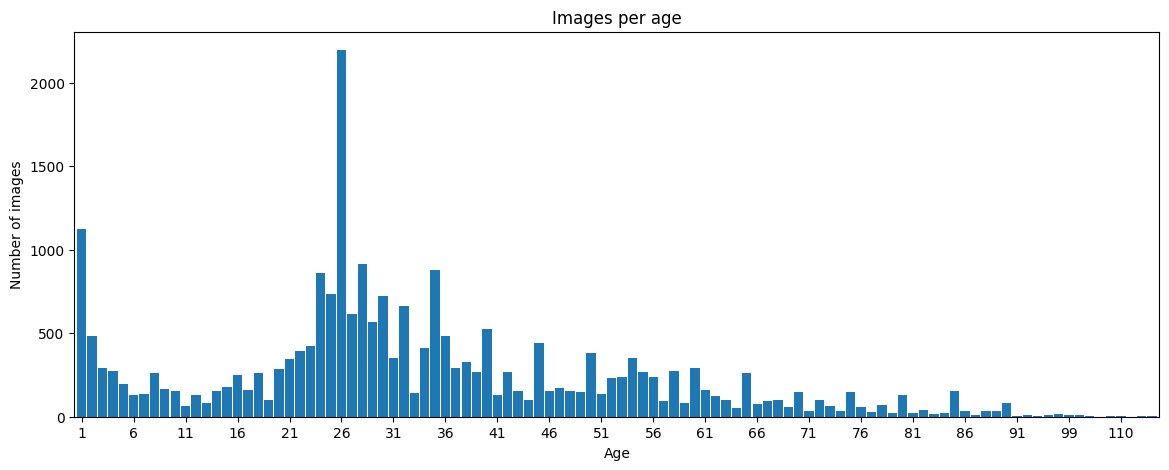

In [39]:
import pandas as pd
import matplotlib.pyplot as plt

ages_series = pd.Series(ages).astype(int)

counts = ages_series.value_counts().sort_index()
print(counts.to_string())

plt.figure(figsize=(14, 5))
counts.plot(kind='bar', width=0.9)
plt.xlabel('Age')
plt.ylabel('Number of images')
plt.title('Images per age')
plt.xticks(range(0, len(counts), 5), counts.index[::5], rotation=0)
plt.show()

## Model

In [40]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

checkpoint = ModelCheckpoint(
    'best_age_model.keras',
    monitor='val_mae',
    mode='min',
    save_best_only=True,
    verbose=1
)

early_stop = EarlyStopping(
    monitor='val_mae',
    mode='min',
    patience=10,
    restore_best_weights=True
)



In [46]:
set_random_seed(42)

model = Sequential([
    Input(shape=(64, 64, 3)),
    RandomFlip("horizontal"),
    Flatten(),

    Dense(512, activation='relu'),
    BatchNormalization(),

    Dense(256, activation='relu'),
    BatchNormalization(),

    Dense(128, activation='relu'),
    BatchNormalization(),

    Dense(64, activation='relu'),
    Dense(1)
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │     6,291,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,468,097 (24.67 MB)

 Trainable params: 6,466,305 (24.67 MB)

 Non-trainable params: 1,792 (7.00 KB)

In [48]:
model.compile(loss='mae', metrics=['mae'])

In [49]:
history = model.fit(train_ds, validation_data=test_ds, epochs=100, callbacks=[checkpoint, early_stop])

Epoch 1/100
260/260 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step - loss: 20.8002 - mae: 16.7597
Epoch 1: val_mae improved from None to 13.71626, saving model to best_age_model.keras

Epoch 1: finished saving model to best_age_model.keras
260/260 ━━━━━━━━━━━━━━━━━━━━ 50s 178ms/step - loss: 15.8897 - mae: 13.1449 - val_loss: 13.7163 - val_mae: 13.7163
Epoch 2/100
260/260 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - loss: 12.1792 - mae: 10.4725
Epoch 2: val_mae improved from 13.71626 to 10.17836, saving model to best_age_model.keras

Epoch 2: finished saving model to best_age_model.keras
260/260 ━━━━━━━━━━━━━━━━━━━━ 88s 201ms/step - loss: 12.1050 - mae: 10.4025 - val_loss: 10.1784 - val_mae: 10.1784
Epoch 3/100
260/260 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step - loss: 11.9749 - mae: 10.3241
Epoch 3: val_mae did not improve from 10.17836
260/260 ━━━━━━━━━━━━━━━━━━━━ 80s 194ms/step - loss: 11.5657 - mae: 10.0287 - val_loss: 12.3736 - val_mae: 12.3736
Epoch 4/100
260/260 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - loss: 10

## HISTORY

In [54]:
hist = pd.DataFrame(history.history)
hist

,loss,mae,val_loss,val_mae
0,15.889666,13.144905,13.716265,13.716265
1,12.105022,10.402472,10.178364,10.178364
2,11.565664,10.028707,12.373629,12.373629
3,11.088009,9.614858,12.351345,12.351345
4,10.810664,9.446896,21.558466,21.558466
5,10.500846,9.175550,15.343534,15.343534
6,10.187674,8.916065,9.773413,9.773413
7,9.915652,8.765191,11.928485,11.928485
8,9.754575,8.627915,11.002940,11.002940
9,9.617395,8.449792,12.163360,12.163360


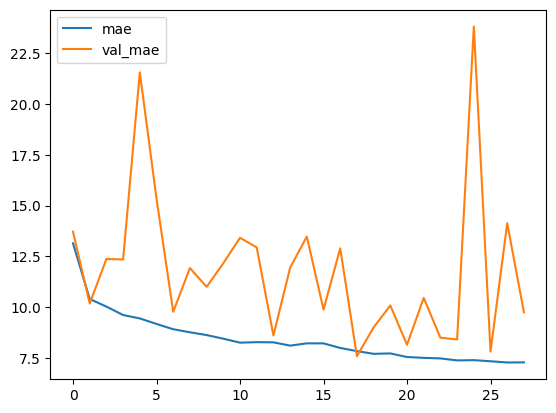

In [55]:
hist[['mae', 'val_mae']].plot()
plt.show()

## PREDICTING

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step


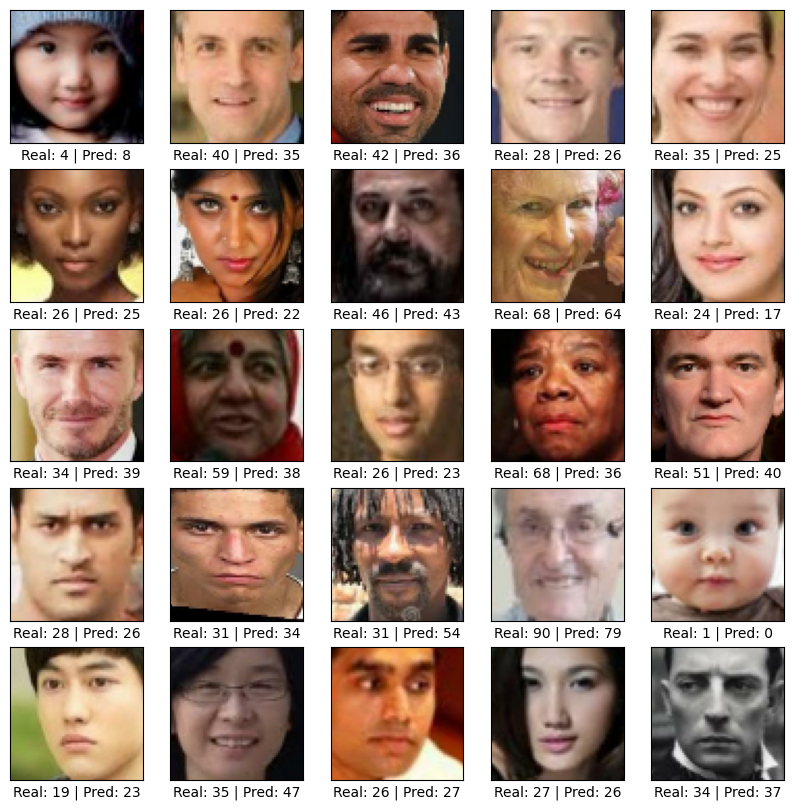

In [56]:
test_images, test_ages = next(iter(test_ds))
preds = model.predict(test_images).flatten()

plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(test_images[i])
    plt.xticks([])
    plt.yticks([])
    plt.xlabel(f"Real: {int(test_ages[i])} | Pred: {int(preds[i])}")
plt.show()

In [60]:
all_preds, all_true = [], []
for x, y in test_ds:
    all_preds.append(model.predict(x, verbose=0).flatten())
    all_true.append(y.numpy())
all_preds, all_true = np.concatenate(all_preds), np.concatenate(all_true)

test_mae = mean_absolute_error(all_true, all_preds)
test_rmse = np.sqrt(mean_squared_error(all_true, all_preds))
test_r2 = r2_score(all_true, all_preds)
print(f"Test MAE : {test_mae:.2f} years")
print(f"Test RMSE: {test_rmse:.2f} years")
print(f"Test R²  : {test_r2:.3f}")

Test MAE : 7.59 years
Test RMSE: 11.09 years
Test R²  : 0.686


In [61]:
df = pd.DataFrame({'true': all_true, 'err': np.abs(all_true - all_preds), 'signed': all_preds - all_true})
df['group'] = pd.cut(df['true'], [0, 10, 20, 30, 40, 50, 60, 70, 90])
print(df.groupby('group', observed=True).agg(MAE=('err', 'mean'), mean_signed_error=('signed', 'mean'), count=('err', 'count')).round(1))

           MAE  mean_signed_error  count
group                                   
(0, 10]    4.1                3.5   2238
(10, 20]   6.1                3.8   1175
(20, 30]   5.3                0.5   5442
(30, 40]   7.8               -2.9   3019
(40, 50]  10.2               -6.5   1479
(50, 60]  12.7               -8.6   1562
(60, 70]  13.8               -9.3    826
(70, 90]  13.1               -9.9    791


IndexError: index 10898 is out of bounds for axis 0 with size 7106

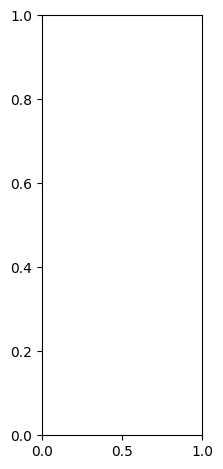

In [77]:
errors = np.abs(all_true - all_preds)
worst = np.argsort(errors)[::-1][:25]

plt.figure(figsize=(12, 12))
for k, idx in enumerate(worst):
    plt.subplot(2, 5, k + 1)
    plt.imshow(Image.open(test_paths[idx]))
    plt.xticks([]); plt.yticks([])
    plt.xlabel(f"Real: {int(all_true[idx])} | Pred: {int(round(all_preds[idx]))}", fontsize=8)
plt.suptitle("Worst 25 predictions on the test set")
plt.tight_layout()
plt.show()

### BONUS

In [76]:
from tensorflow.keras.callbacks import EarlyStopping as _ES   # لا نستخدم checkpoint عشان ما نكتب فوق best_age_model.keras

set_random_seed(42)
model_base = Sequential([
    Input(shape=(64, 64, 3)),
    Flatten(),
    Dense(500, activation='relu'),
    Dense(300, activation='relu'),
    Dense(100, activation='relu'),
    Dense(1)
])
model_base.compile(optimizer='adam', loss='mse', metrics=['mae'])
hist_base = model_base.fit(train_ds, validation_data=test_ds, epochs=30,
                           callbacks=[_ES(monitor='val_mae', mode='min', patience=5, restore_best_weights=True)])

plt.figure(figsize=(8, 5))
plt.plot(hist_base.history['val_mae'], label='Baseline (simple Dense) val MAE')
plt.plot(history.history['val_mae'], label='Improved model val MAE')
plt.xlabel('Epoch'); plt.ylabel('Validation MAE (years)')
plt.title('Learning curves: baseline vs improved'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

print("Baseline best val MAE:", min(hist_base.history['val_mae']))
print("Improved best val MAE:", min(history.history['val_mae']))

Epoch 1/30
260/260 ━━━━━━━━━━━━━━━━━━━━ 48s 172ms/step - loss: 598.6840 - mae: 16.2156 - val_loss: 334.5886 - val_mae: 13.9274
Epoch 2/30
 72/260 ━━━━━━━━━━━━━━━━━━━━ 39s 208ms/step - loss: 422.2394 - mae: 14.1583

KeyboardInterrupt: 

## SAVING THE MODEL

In [ ]:
model.save('age_model.keras')

In [ ]:
# import os
# print(os.path.abspath('age_model.keras'))
# print(os.path.exists('age_model.keras'))

In [ ]:
!pip install -q gradio

In [ ]:
import gradio as gr
import numpy as np
import tensorflow as tf

In [ ]:
model = tf.keras.models.load_model('best_age_model.keras')

def predict_age(img):
    if img is None:
        return "Please upload or capture a face image"

    img = tf.image.resize(img, [64, 64]) / 255.0
    img = tf.expand_dims(img, axis=0)

    pred = model.predict(img, verbose=0)[0][0]
    pred = max(0, int(round(pred)))
    return f"Predicted age: {pred} years"

demo = gr.Interface(
    fn=predict_age,
    inputs=gr.Image(sources=["upload", "webcam"], type="numpy", label="Face Image"),
    outputs=gr.Textbox(label="Result"),
    title="Age Prediction from Image",
    description="Upload an image or take a photo with your camera",
)

demo.launch(share=True)